# Numerical computing: making correct mathematics executable

## 1. Introduction and learning objectives

Equivalent algebraic formulas can behave differently in floating point. This chapter reviews the applied tools needed to recognize cancellation, stabilize probability calculations, solve linear systems, control randomness, and bound memory. You should leave able to separate implementation error, an ill-conditioned problem, and a statistical failure.

**Diagnostic:** complete the next two exercises and predict which of float32 and float64 can distinguish 100000000 from 100000001. If these are familiar, skim the theory and complete the solver, streaming, and conditioning investigations.

**Study workflow:** attempt each dedicated answer first, then reveal its hint or worked solution. Reference Python is displayed Markdown and is not executed by Run All. Snippet dependencies refer only to this chapter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 00.03.01 — Identify lost information

**Type:** Numerical · **Answer:** Markdown

Predict `np.float32(1e8) + np.float32(1) - np.float32(1e8)`. Compare it with the same expression in float64. Explain why converting the final float32 result to float64 cannot repair it.

**Expected outcome:** two results and an explanation in terms of representable spacing.

**Your response to Exercise 00.03.01**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.03.01**

Precision is relative to magnitude; float32 spacing near 1e8 is larger than one.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.03.01**

The float32 result is zero, while float64 gives one. Rounding loses the increment during the addition, before the subtraction. Converting zero to float64 preserves zero; higher precision must be used before the information-losing operation. Machine epsilon is spacing near one, not a universal absolute accuracy bound.

</details>

### Exercise 00.03.02 — Stabilize a log sum

**Type:** Mathematical · **Answer:** Markdown

Derive log(exp(a)+exp(b)) using a maximum shift. Evaluate its scale for a=1000, b=999 without exponentiating 1000.

**Expected outcome:** a finite expression and an explanation of why the largest shifted exponential is one.

**Your response to Exercise 00.03.02**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.03.02**

Factor exp(max(a,b)) out of the sum inside the logarithm.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.03.02**

Let m=max(a,b). The expression is m+log(exp(a−m)+exp(b−m)). Here it is 1000+log(1+exp(−1)), approximately 1000.3132617. The shifted exponents are nonpositive, avoiding overflow. Extremely small terms can still underflow; their contribution is negligible at that scale. This finite-input derivation does not by itself specify behavior when all inputs are minus infinity.

</details>

## 2. Prerequisites and mathematical foundations

Float32 has approximately seven decimal significant digits; float64 approximately sixteen. Operations are rounded to representable values. Non-associativity follows: (a+b)+c may differ from a+(b+c). Relative error is useful away from zero; absolute error is essential near zero. Check both when comparing gradients.

Cancellation subtracts nearby rounded values. For small x, evaluating √(1+x)−1 directly loses relative accuracy; rationalizing gives x/(√(1+x)+1). `log1p(x)` and `expm1(x)` similarly preserve small increments. Changing formulas can improve numerical stability without changing the underlying problem's conditioning.

An algorithm is backward stable when its output solves a nearby input problem. A problem is well conditioned when small input changes produce small output changes. For an invertible matrix A, κ₂(A)=||A||₂||A⁻¹||₂ is a worst-case amplification measure. A small residual does not alone guarantee small solution error when κ is large. Condition numbers are sensitivity bounds, not predictions that every right-hand side will attain the worst case.

## 3. Theoretical development and worked examples

### Stable log-domain calculations

For finite logits z, softplus(z)=log(1+exp(z)) is `logaddexp(0,z)`. The derivative is sigmoid(z). Calculate sigmoid with separate signs:

$$\sigma(z)=\begin{cases}1/(1+e^{-z})&z\geq0\\e^z/(1+e^z)&z<0.\end{cases}$$

Both exponential arguments are nonpositive. A vectorized `where` expression may evaluate both branches before selecting, so explicit masked assignments avoid overflow. Mean binary cross-entropy can be evaluated as mean(softplus(z)−yz), with derivative (σ(z)−y)/n. The finite-logit calculation avoids taking log of rounded probabilities zero or one.

### Solves and residuals

To solve Ax=b, call a linear solver rather than explicitly forming A⁻¹. A useful normwise backward residual is

$$\eta=\frac{\|A\hat x-b\|_2}{\|A\|_2\|\hat x\|_2+\|b\|_2}.$$

For A=diag(1,10⁻⁶), an error of 10⁻⁶ in the second component of b changes that solution component by one. A tiny residual is compatible with a large forward error relative to the original intended x. Regularizing a singular system changes the problem and must be reported; silently using a pseudoinverse is not a neutral repair.

### Randomness and streaming state

Use local `default_rng(seed)` instances rather than relying on global state. Record the NumPy version, seeds, data order, split procedure, dtype, and thread configuration. A seed reproduces one specified computation; it does not guarantee identical floating-point reductions across devices or future library versions. Separate random streams for data, splits, and initialization avoid accidental coupling.

Welford's recurrence maintains count n, mean m, and sum of squared deviations M₂. For each x: increment n, let δ=x−m, set m←m+δ/n, then M₂←M₂+δ(x−m). The final population-convention variance is M₂/n, or sample variance M₂/(n−1). This avoids the severe cancellation in E[X²]−E[X]² for data with a large offset.

## 4. Guided exercises

### Exercise 00.03.03 — Budget before allocating

**Type:** Conceptual · **Answer:** Markdown

A pairwise float64 distance matrix has 100000 rows and columns. Estimate its storage in GiB, excluding temporaries. Propose a bounded-memory computation if only nearest distances are needed.

**Expected outcome:** a byte calculation and a chunking design compatible with 6 GiB host working memory.

**Your response to Exercise 00.03.03**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.03.03**

Multiply the number of entries by eight and divide by 2³⁰. Do not allocate the matrix.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.03.03**

The matrix alone requires 80,000,000,000 bytes, approximately 74.5 GiB. Process query and reference blocks, updating running nearest distances or top-k candidates and discarding each block. Choose block sizes using input, output, and temporary-array memory together. Chunking limits storage but does not eliminate the quadratic arithmetic cost; approximate methods later trade accuracy for speed.

</details>

## 5. Implementation challenges

### Exercise 00.03.04 — Implement a finite-input logsumexp

**Type:** Programming · **Answer:** Code

Implement `stable_logsumexp(values, axis=None, keepdims=False)` for nonempty finite arrays. Explicitly reject infinities and NaNs in this exercise. Compare reductions over rows, columns, and all entries.

**Expected outcome:** correct shapes and finite values for [1000,999], with an independent `np.logaddexp.reduce` check.

In [ ]:
# Your code for Exercise 00.03.04.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.03.04**

Keep dimensions through the maximum and sum, then squeeze only the reduced axes.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.03.04**

The finite-domain contract avoids an undefined infinity-minus-infinity shift. A production implementation may add special cases for infinite inputs; it must specify them deliberately.

~~~python
def stable_logsumexp(values, axis=None, keepdims=False):
    a = np.asarray(values, dtype=float)
    if a.size == 0 or not np.isfinite(a).all():
        raise ValueError("nonempty finite inputs required")
    maximum = np.max(a, axis=axis, keepdims=True)
    result = maximum + np.log(np.sum(np.exp(a - maximum), axis=axis, keepdims=True))
    return result if keepdims else np.squeeze(result, axis=axis)
~~~

</details>

### Exercise 00.03.05 — Stabilize softplus and its derivative

**Type:** Programming · **Answer:** Code

Implement `softplus_sigmoid(z)` returning softplus and sigmoid for finite scalars or arrays. Avoid overflowing even temporarily at logits ±1000.

**Expected outcome:** sigmoid [0,.5,1] at [−1000,0,1000], softplus approximately [0,log(2),1000], and derivative agreement on moderate inputs.

In [ ]:
# Your code for Exercise 00.03.05.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.03.05**

Use logaddexp for the value and masked branches for the derivative.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.03.05**

The derivative saturates to machine zero or one at extremes, which is expected rounding. That does not justify computing cross-entropy through log of those rounded probabilities.

~~~python
def softplus_sigmoid(z):
    z = np.asarray(z, dtype=float)
    if not np.isfinite(z).all():
        raise ValueError("finite logits required")
    p = np.empty_like(z)
    positive = z >= 0
    p[positive] = 1 / (1 + np.exp(-z[positive]))
    e = np.exp(z[~positive])
    p[~positive] = e / (1 + e)
    return np.logaddexp(0, z), p
~~~

</details>

### Exercise 00.03.06 — Solve and report sensitivity

**Type:** Programming · **Answer:** Code

Implement `solve_checked(A, b)` for a nonempty finite square matrix and a finite vector b. Return solution, normalized backward residual, and 2-norm condition number. Let a singular solve raise an error. Define a zero residual denominator as zero only when the numerator is also zero.

**Expected outcome:** exact small-system agreement, diagnostics, and an explicit singular-system failure.

In [ ]:
# Your code for Exercise 00.03.06.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.03.06**

Calculate b's shape explicitly to prevent an unintended multi-right-hand-side broadcast.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.03.06**

The returned condition number describes the supplied floating-point matrix. If it was rounded from a different intended matrix, that input change must also be considered. No inverse is explicitly formed.

~~~python
def solve_checked(A, b):
    A, b = np.asarray(A, dtype=float), np.asarray(b, dtype=float)
    if A.ndim != 2 or A.shape[0] == 0 or A.shape[0] != A.shape[1] or b.shape != (len(A),):
        raise ValueError("expected square A and vector b")
    if not np.isfinite(A).all() or not np.isfinite(b).all():
        raise ValueError("finite system required")
    x = np.linalg.solve(A, b)
    numerator = np.linalg.norm(A @ x - b)
    denominator = np.linalg.norm(A, 2) * np.linalg.norm(x) + np.linalg.norm(b)
    residual = numerator / denominator if denominator else (0.0 if numerator == 0 else np.inf)
    return x, float(residual), float(np.linalg.cond(A))
~~~

</details>

### Exercise 00.03.07 — Accumulate stable streaming moments

**Type:** Programming · **Answer:** Code

Implement `streaming_moments(chunks, ddof=1)` over an iterable of finite one-dimensional chunks. Ignore empty chunks, require ddof∈{0,1} and total n>ddof. Return count, mean, variance. Do not concatenate chunks.

**Expected outcome:** agreement with a centered two-pass calculation and storage independent of total stream length.

In [ ]:
# Your code for Exercise 00.03.07.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.03.07**

Update M₂ using the old-mean and new-mean residuals, not the same residual twice.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.03.07**

This scalar recurrence uses constant auxiliary state. Input chunk storage is owned by the producer. Even stable algorithms have rounding error; test large-offset data with scale-aware tolerances instead of exact equality.

~~~python
def streaming_moments(chunks, ddof=1):
    if ddof not in (0, 1):
        raise ValueError("ddof must be zero or one")
    count, mean, m2 = 0, 0.0, 0.0
    for chunk in chunks:
        chunk = np.asarray(chunk, dtype=float)
        if chunk.ndim != 1 or not np.isfinite(chunk).all():
            raise ValueError("finite vector chunks required")
        for value in chunk:
            count += 1
            delta = value - mean
            mean += delta / count
            m2 += delta * (value - mean)
    if count <= ddof:
        raise ValueError("insufficient observations")
    return count, float(mean), float(m2 / (count - ddof))
~~~

</details>

## 6. Experiments and visualizations

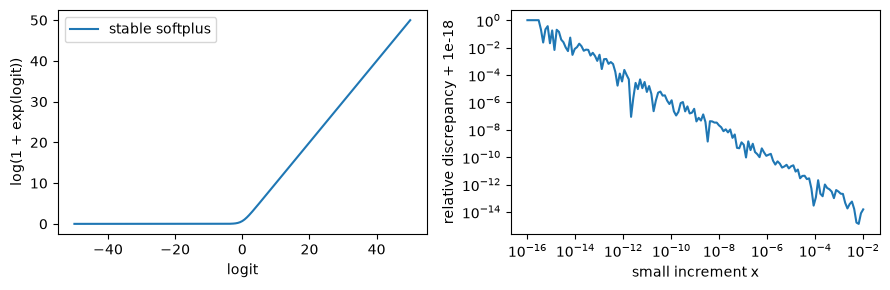

In [2]:
z = np.linspace(-50, 50, 301)
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(z, np.logaddexp(0, z), label="stable softplus")
axes[0].set(xlabel="logit", ylabel="log(1 + exp(logit))")
axes[0].legend()
x = np.logspace(-16, -2, 150)
direct = np.sqrt(1 + x) - 1
rationalized = x / (np.sqrt(1 + x) + 1)
axes[1].loglog(x, np.abs(direct - rationalized) / rationalized + 1e-18)
axes[1].set(xlabel="small increment x", ylabel="relative discrepancy + 1e-18")
fig.tight_layout()
plt.show()

### Exercise 00.03.08 — Observe overflow without hiding it

**Type:** Experimental · **Answer:** Code

Compare naive and stable softplus at −1000, −50, 0, 50, 1000. Record which results are finite and compare the stable derivative with finite differences at moderate points.

**Expected outcome:** a table that identifies the intended naive overflow, plus derivative errors and step size.

In [ ]:
# Your code for Exercise 00.03.08.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.03.08**

Use a local errstate only around the intentionally unstable expression.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.03.08**

This depends on `softplus_sigmoid`. Suppressing an expected warning in one demonstration is not a reason to suppress numerical warnings throughout training. Inspect actual values and finiteness.

~~~python
points = np.array([-1000., -50., 0., 50., 1000.])
with np.errstate(over="ignore"):
    naive = np.log(1 + np.exp(points))
stable, derivative = softplus_sigmoid(points)
print(np.column_stack([points, naive, stable, np.isfinite(naive)]))
moderate = np.array([-3., .2, 4.])
h = 1e-5
numeric = (np.logaddexp(0, moderate + h) - np.logaddexp(0, moderate - h)) / (2 * h)
print("derivative discrepancies", numeric - softplus_sigmoid(moderate)[1])
~~~

</details>

### Exercise 00.03.09 — Separate conditioning from precision

**Type:** Experimental · **Answer:** Code

For A=[[1,1],[1,1+δ]] with δ in {1e−4,1e−7,1e−10}, construct b in float64 from intended x=[1,−1], then solve cast copies in float32 and float64. Record condition numbers, forward errors, and singular failures.

**Expected outcome:** an actual table with failures retained, rather than replaced by a different problem.

In [ ]:
# Your code for Exercise 00.03.09.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.03.09**

Construct b before dtype conversion; otherwise you may unintentionally compare different intended problems.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.03.09**

The exercise intentionally calls the dtype-preserving solver directly rather than `solve_checked`, whose contract converts inputs to float64. A float32 matrix can round to exact singularity. An exception is evidence, not a missing value to hide.

~~~python
truth = np.array([1., -1.])
for delta in (1e-4, 1e-7, 1e-10):
    A64 = np.array([[1., 1.], [1., 1. + delta]])
    b64 = A64 @ truth
    for dtype in (np.float32, np.float64):
        A, b = A64.astype(dtype), b64.astype(dtype)
        try:
            estimate = np.linalg.solve(A, b)
            print(delta, dtype.__name__, np.linalg.cond(A), np.linalg.norm(estimate - truth))
        except np.linalg.LinAlgError:
            print(delta, dtype.__name__, "singular after conversion")
~~~

</details>

### Exercise 00.03.10 — Check a streaming calculation

**Type:** Experimental · **Answer:** Code

Generate 1200 observations near 1e6 with standard deviation .1. Compare streaming variance over chunks of 17 with a centered two-pass variance and with E[X²]−E[X]². Report dtype and discrepancy.

**Expected outcome:** measured numerical errors and a memory estimate, with no large allocation.

In [ ]:
# Your code for Exercise 00.03.10.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.03.10**

Generate a small retained sample to provide an independent oracle; a real stream need not retain it.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.03.10**

This depends on `streaming_moments`. The retained array is a verification convenience. A producer yielding chunks would make the accumulation memory independent of total n; the loop's Python overhead may limit throughput.

~~~python
values = 1e6 + np.random.default_rng(31).normal(0, .1, 1200)
count, mean, variance = streaming_moments((values[i:i+17] for i in range(0, len(values), 17)), ddof=0)
centered = np.mean((values - values.mean())**2)
naive = np.mean(values**2) - values.mean()**2
print(count, mean, variance, centered, naive)
print("chunk payload bytes", 17 * values.itemsize)
~~~

</details>

## 7. Interpretation and critical analysis

### Exercise 00.03.11 — Interpret a tiny residual

**Type:** Critical · **Answer:** Markdown

A solver returns backward residual 1e−15 on a matrix with condition number 1e14. An author concludes that all solution components have fifteen accurate digits. Evaluate the conclusion.

**Expected outcome:** distinguish backward and forward error, input rounding, and a worst-case bound.

**Your response to Exercise 00.03.11**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.03.11**

Sensitivity can amplify a small backward perturbation; the condition number is not a certificate of componentwise accuracy.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.03.11**

The residual supports a small normwise backward error for the supplied inputs. Worst-case forward sensitivity can amplify that error by about κ, so fifteen correct digits are not justified. The exact forward error also depends on perturbation directions, scaling, and the right-hand side. Compare with known truth or a higher-precision reference when possible and report conditioning and residual together.

</details>

## 8. Review questions and knowledge checks

### Exercise 00.03.12 — Specify reproducibility honestly

**Type:** Conceptual · **Answer:** Markdown

Two experiments use seed 7, but one consumes a random minibatch before creating its train/test split. Must their splits agree? What should be recorded for a later reproduction?

**Expected outcome:** explain stream state and give a concrete recording policy.

**Your response to Exercise 00.03.12**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 00.03.12**

A random generator is stateful; a seed initializes a sequence, not every individual operation.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 00.03.12**

The splits need not agree because the generators reach different states. Use separate named seeds or spawned streams for data, splits, and optimization, and record operation order, library versions, dtype, hardware, and thread configuration. Matching a seed alone does not guarantee matching algorithms or arithmetic across environments.

</details>

## 9. Summary and next learning steps

You can now audit formulas for rounding and overflow, distinguish conditioning from algorithm stability, and predict storage before allocating. Complete the [mathematical audit](../../projects/00-mathematical-audit/mathematical-audit.ipynb), then start [linear regression](../01-ml-fundamentals/linear-regression.ipynb).

Targeted reference: [NumPy linear solve](https://numpy.org/doc/stable/reference/generated/numpy.linalg.solve.html). A successful numerical check needs a stated domain, independent expected result, tolerance, and failure interpretation.